# Covariance Steering for Stochastic Path Planning: A Step-by-Step Walkthrough

This notebook rebuilds, from first principles, the method of

> K. Okamoto and P. Tsiotras, **"Optimal Stochastic Vehicle Path Planning Using Covariance Steering,"** *IEEE Robotics and Automation Letters*, 4(3):2276–2281, 2019.

**The question.** A vehicle must drive from a start to a goal in a fixed time while random disturbances push it around. A normal planner plans only the *average* path, so the uncertainty around it grows. Near obstacles, that growing uncertainty forces wide detours. The paper asks: **if the planner also controls *how much* the vehicle can spread out, can it take shorter, narrower routes, and is that worth the extra control effort?**

**How every section works.**

1. **Idea:** what we want and why.
2. **Derivation:** the equations, built up step by step.
3. **Code:** the equation turned into a few lines of Python, using the paper's symbol names.
4. **What it does:** a plot or numerical check that shows the equation working. Most checks compare a formula with a Monte Carlo simulation of the actual noisy system.

| § | Topic | Paper |
|---|---|---|
| 1 | Setup and parameters | Sec. IV-B |
| 2 | The vehicle model | Eq. 1 |
| 3 | Writing the whole trajectory as one equation | Eq. 7 |
| 4 | Open loop: why uncertainty only grows | Sec. I |
| 5 | The feedback policy and why it stays convex | Theorem 1, Eqs. 12–16 |
| 6 | The expected cost | Eq. 17 |
| 7 | Terminal constraints, and the first optimal controller | Eqs. 18–19 |
| 8 | Chance constraints: probabilistic safety | Eq. 20 |
| 9 | Obstacles: mixed-integer region selection | Eqs. 22–25, Algorithm 1 |
| 10 | Experiment 1: the double slit | Fig. 2 |
| 11 | Experiment 2: narrower slit, and why the route switches | Fig. 4 |
| 12 | Verification by Monte Carlo | — |
| 13 | Summary | — |

**To run:** select the kernel **Python (covsteer)**. Most cells run in under a second. The mixed-integer solves in §10–11 take about 1 minute each.
Companion files: `../covsteer_repro.py` (the same method as a script, `--step 0..8`) and `../slides/`.

In [1]:
import json
import time
import warnings
from pathlib import Path

import cvxpy as cp
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle
from scipy.stats import norm as std_normal

# Okabe-Ito colour-blind-safe palette
BLUE, ORANGE, VERMILLION = "#0072B2", "#E69F00", "#D55E00"
GREEN, PURPLE, SKY, GRAY = "#009E73", "#CC79A7", "#56B4E9", "0.55"

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 10, "axes.titlesize": 10})
RESULTS_DIR = Path("..") / "results"
# MOSEK's Python API warns that it copies index arrays; harmless, so hide it
warnings.filterwarnings("ignore", message="Argument sub", category=UserWarning)
SOLVER = cp.MOSEK if "MOSEK" in cp.installed_solvers() else cp.CLARABEL
print("cvxpy", cp.__version__, "| solver:", SOLVER)

cvxpy 1.9.3 | solver: MOSEK


In [2]:
def ellipse_xy(mean_2d, cov_2d, n_sigma=3, n_pts=80):
    """Points on the n-sigma ellipse of a 2-D Gaussian (for plotting).

    Args:
        mean_2d: centre, shape (2,).
        cov_2d: 2x2 covariance.
        n_sigma: how many standard deviations the ellipse spans.
        n_pts: number of points on the curve.

    Returns:
        (x, y) arrays of the ellipse boundary.
    """
    vals, vecs = np.linalg.eigh(cov_2d)
    t = np.linspace(0, 2 * np.pi, n_pts)
    circle = np.vstack([np.cos(t), np.sin(t)])
    pts = mean_2d[:, None] + n_sigma * vecs @ (np.sqrt(np.maximum(vals, 0))[:, None] * circle)
    return pts[0], pts[1]

---
## 1. Setup and Parameters

The vehicle moves in the plane for $N=20$ steps of $\Delta t=0.2$ s (4 seconds in total).

| Symbol | Meaning | Value | Source |
|---|---|---|---|
| $\Delta t,\ N$ | time step, horizon | 0.2 s, 20 | paper |
| $D$ | noise scaling | $10^{-2} I_4$ | paper |
| $\epsilon$ | allowed violation probability (per constraint face) | $10^{-3}$ | paper |
| bounds | on nominal control $V$ and feedback gains $K$ | $\lvert V\rvert\le 100$, $\lvert K\rvert \le 10$ | paper |
| $\mu_0$, $\Sigma_0$ | start distribution | $(-10, 0.1, 0, 0)$, diag(0.05, 0.05, 0.001, 0.001) | **assumed** |
| $\mu_N$, $\Sigma_N$ | target distribution | $0$, diag(0.01, 0.01, 0.001, 0.001) | **assumed** |
| $Q_k$, $R_k$ | cost weights | $0$, $I_2$ | **assumed** |

The paper does not list $\mu_0, \Sigma_0, \Sigma_N, Q, R$. We chose them so that the $3\sigma$ start and target circles have the sizes drawn in the paper's Fig. 2. With $Q=0, R=I$ the cost is simply the **expected control energy**.

In [3]:
dt, N = 0.2, 20                 # time step, horizon (steps k = 0..N)
nx, nu, nw = 4, 2, 4            # sizes of state, control, noise
eps = 1e-3                      # chance-constraint risk per face

mu_0 = np.array([-10.0, 0.1, 0.0, 0.0])          # ASSUMED
Sigma_0 = np.diag([0.05, 0.05, 0.001, 0.001])   # ASSUMED
mu_N = np.zeros(nx)                              # ASSUMED
Sigma_N = np.diag([0.01, 0.01, 0.001, 0.001])   # ASSUMED

Q_k = np.zeros((nx, nx))        # ASSUMED: no state penalty
R_k = np.eye(nu)                # ASSUMED: control energy
V_MAX, K_MAX = 100.0, 10.0      # paper, Sec. IV-B

print(f"start: 3-sigma radius = {3 * np.sqrt(Sigma_0[0, 0]):.3f}"
      f" | target: 3-sigma radius = {3 * np.sqrt(Sigma_N[0, 0]):.3f}")

start: 3-sigma radius = 0.671 | target: 3-sigma radius = 0.300


---
## 2. The Vehicle Model (Eq. 1)

**Idea.** The simplest model of a vehicle we can push around: we choose the **acceleration** and it integrates to velocity and position (a *double integrator*).

**Derivation.** If the acceleration $a$ is held constant over one step of length $\Delta t$:

$$
v_{k+1} = v_k + \Delta t\, a_k, \qquad
p_{k+1} = p_k + \Delta t\, v_k + \tfrac{1}{2}\Delta t^2\, a_k .
$$

Stack state $x=[p_x,p_y,v_x,v_y]^\top$ and control $u=[a_x,a_y]^\top$, and add random disturbances $w_k\sim\mathcal N(0,I)$:

$$
x_{k+1} = A x_k + B u_k + D w_k, \qquad
A=\begin{bmatrix} I & \Delta t\, I\\ 0 & I\end{bmatrix},\quad
B=\begin{bmatrix} \tfrac12\Delta t^2 I\\ \Delta t\, I\end{bmatrix},\quad
D = 10^{-2} I_4 .
$$

The start state is itself uncertain: $x_0\sim\mathcal N(\mu_0,\Sigma_0)$.

In [4]:
I2, Z2 = np.eye(2), np.zeros((2, 2))
A = np.block([[I2, dt * I2],
              [Z2, I2]])
B = np.vstack([0.5 * dt**2 * I2,
               dt * I2])
D = 1e-2 * np.eye(nx)
print("A =\n", A, "\nB =\n", B)

# sanity check: start at rest, accelerate at 1 m/s^2 in x for one step
x_next = A @ np.zeros(nx) + B @ np.array([1.0, 0.0])
print("after one step: p_x =", x_next[0], "(expect 0.5*0.2^2 = 0.02),  v_x =", x_next[2], "(expect 0.2)")

A =
 [[1.  0.  0.2 0. ]
 [0.  1.  0.  0.2]
 [0.  0.  1.  0. ]
 [0.  0.  0.  1. ]] 
B =
 [[0.02 0.  ]
 [0.   0.02]
 [0.2  0.  ]
 [0.   0.2 ]]
after one step: p_x = 0.020000000000000004 (expect 0.5*0.2^2 = 0.02),  v_x = 0.2 (expect 0.2)


**What it does.** Let's simulate the model with **no control at all** ($u_k=0$) starting from samples of $x_0$, and watch how the cloud of possible positions evolves.

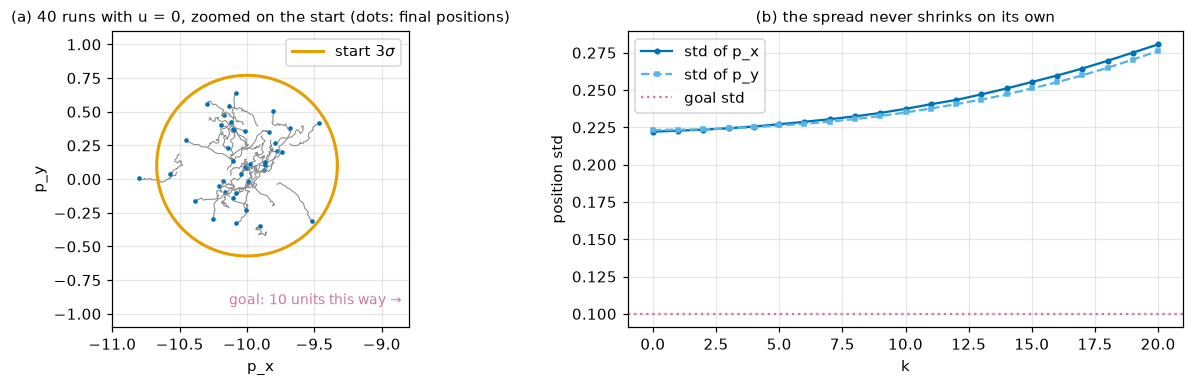

In [5]:
def simulate(V, K_ks=None, n_mc=20_000, seed=1):
    '''Simulate the system under the policy u_k = v_k + K_k y_k (Eq. 12).

    The policy is introduced in Sec. 5; with K_ks=None it is plain open loop.

    Args:
        V: stacked nominal controls, shape (N*nu,).
        K_ks: list of N feedback gains (nu x nx), or None for K = 0.
        n_mc: number of Monte Carlo runs.
        seed: random seed.

    Returns:
        xs: list of N+1 arrays (n_mc x nx), states.
        ys: list of N+1 arrays, auxiliary states y_k.
        us: list of N arrays (n_mc x nu), applied controls.
        cost: array (n_mc,), realized sum_k u_k^T R u_k.
    '''
    g = np.random.default_rng(seed)
    if K_ks is None:
        K_ks = [np.zeros((nu, nx))] * N
    x = g.multivariate_normal(mu_0, Sigma_0, size=n_mc)
    y = x - mu_0                                         # Eq. (13b)
    xs, ys, us, cost = [x], [y], [], np.zeros(n_mc)
    for k in range(N):
        u = V[k * nu:(k + 1) * nu] + y @ K_ks[k].T          # Eq. (12)
        w = g.normal(size=(n_mc, nw))
        x = x @ A.T + u @ B.T + w @ D.T                      # Eq. (1)
        y = y @ A.T + w @ D.T                                # Eq. (13a)
        cost += np.einsum("ni,ij,nj->n", u, R_k, u)
        xs.append(x); ys.append(y); us.append(u)
    return xs, ys, us, cost


xs, *_ = simulate(np.zeros(N * nu), n_mc=5_000, seed=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), layout="constrained")
ax = axes[0]
for i in range(40):
    ax.plot([x[i, 0] for x in xs], [x[i, 1] for x in xs], color=GRAY, lw=0.7)
    ax.plot(xs[-1][i, 0], xs[-1][i, 1], ".", color=BLUE, ms=4)
ax.plot(*ellipse_xy(mu_0[:2], Sigma_0[:2, :2]), color=ORANGE, lw=2, label="start $3\\sigma$")
ax.text(-8.85, -0.9, "goal: 10 units this way \u2192", color=PURPLE, ha="right", va="center", fontsize=9)
ax.set_xlim(-11, -8.8); ax.set_ylim(-1.1, 1.1)
ax.set_aspect("equal"); ax.set_xlabel("p_x"); ax.set_ylabel("p_y"); ax.legend(loc="upper right")
ax.set_title("(a) 40 runs with u = 0, zoomed on the start (dots: final positions)")
ax = axes[1]
ax.plot([x[:, 0].std() for x in xs], "o-", ms=3, color=BLUE, label="std of p_x")
ax.plot([x[:, 1].std() for x in xs], "s--", ms=3, color=SKY, label="std of p_y")
ax.axhline(np.sqrt(Sigma_N[0, 0]), color=PURPLE, ls=":", label="goal std")
ax.set_xlabel("k"); ax.set_ylabel("position std"); ax.legend()
ax.set_title("(b) the spread never shrinks on its own")
plt.show()

Without control nothing moves the vehicle toward the goal (10 units away), and the spread slowly **grows**: the initial velocity uncertainty and the noise both add up over time. A controller has two jobs: **move the centre** of the cloud to the goal, and **keep the cloud small**.

---
## 3. The Whole Trajectory as One Equation (Eq. 7)

**Idea.** An optimizer needs to choose **all** 20 controls at once. To do that, we want every state $x_k$ written directly as a function of the start $x_0$, the controls, and the noise.

**Derivation.** Unroll Eq. (1):

$$
\begin{aligned}
x_1 &= A x_0 + B u_0 + D w_0\\
x_2 &= A^2 x_0 + AB\,u_0 + B u_1 + AD\,w_0 + D w_1\\
&\ \,\vdots\\
x_k &= A^k x_0 + \sum_{j=0}^{k-1} A^{k-1-j}\big(B u_j + D w_j\big).
\end{aligned}
$$

Stack everything: $X=[x_0;\dots;x_N]$, $U=[u_0;\dots;u_{N-1}]$, $W=[w_0;\dots;w_{N-1}]$. Then

$$
\boxed{X = \mathcal A x_0 + \mathcal B U + \mathcal D W}
\qquad
\mathcal A = \begin{bmatrix} I\\ A\\ A^2\\ \vdots\end{bmatrix},\quad
\mathcal B_{kj} = \begin{cases} A^{k-1-j}B & j<k\\ 0 & j\ge k\end{cases}
$$

and similarly for $\mathcal D$. The zero blocks for $j\ge k$ express **causality**: a control applied at time $j$ cannot affect earlier states.

The point is that **$X$ is linear in $U$**. Any linear or convex condition on states becomes a linear or convex condition on the controls.

We also need $E_k$, the matrix that picks $x_k$ out of $X$: $\;x_k=E_kX$.

In [6]:
def lifted_matrices(A, B, D, N):
    """Build the stacked matrices of Eq. (7): X = A_cal x0 + B_cal U + D_cal W.

    Args:
        A, B, D: one-step system matrices.
        N: horizon.

    Returns:
        A_cal ((N+1)nx x nx), B_cal ((N+1)nx x N nu), D_cal ((N+1)nx x N nw).
    """
    A_pow = [np.linalg.matrix_power(A, k) for k in range(N + 1)]
    A_cal = np.vstack(A_pow)
    B_cal = np.zeros(((N + 1) * nx, N * nu))
    D_cal = np.zeros(((N + 1) * nx, N * nw))
    for k in range(1, N + 1):              # block row  -> x_k
        for j in range(k):                 # block col  -> u_j, w_j  (j < k only)
            rows = slice(k * nx, (k + 1) * nx)
            B_cal[rows, j * nu:(j + 1) * nu] = A_pow[k - 1 - j] @ B
            D_cal[rows, j * nw:(j + 1) * nw] = A_pow[k - 1 - j] @ D
    return A_cal, B_cal, D_cal


def E(k):
    """Selector E_k with x_k = E_k X (Eqs. 9-10)."""
    E_k = np.zeros((nx, (N + 1) * nx))
    E_k[:, k * nx:(k + 1) * nx] = np.eye(nx)
    return E_k


A_cal, B_cal, D_cal = lifted_matrices(A, B, D, N)
print("A_cal", A_cal.shape, " B_cal", B_cal.shape, " D_cal", D_cal.shape)

A_cal (84, 4)  B_cal (84, 40)  D_cal (84, 80)


max |loop - lifted| = 1.3e-15


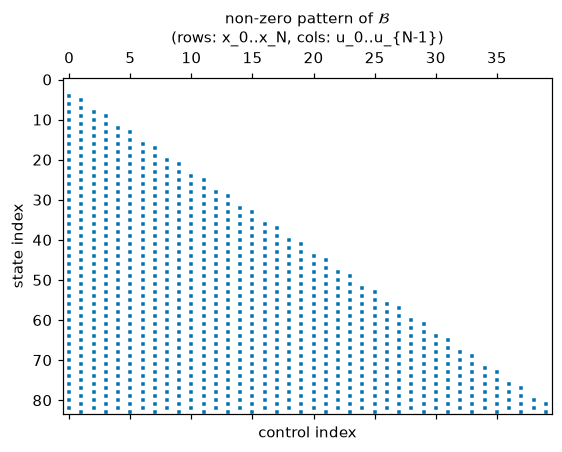

In [7]:
# Check: stepping Eq. (1) twenty times == one multiplication with Eq. (7)
g = np.random.default_rng(3)
x0, U, W = g.normal(size=nx), g.normal(size=N * nu), g.normal(size=N * nw)
x, X_loop = x0, [x0]
for k in range(N):
    x = A @ x + B @ U[k * nu:(k + 1) * nu] + D @ W[k * nw:(k + 1) * nw]
    X_loop.append(x)
X_loop = np.concatenate(X_loop)
X_lift = A_cal @ x0 + B_cal @ U + D_cal @ W
print(f"max |loop - lifted| = {np.abs(X_loop - X_lift).max():.1e}")

fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
ax.spy(np.abs(B_cal) > 0, markersize=1.5, color=BLUE, aspect="auto")
ax.set_title("non-zero pattern of $\\mathcal{B}$\n(rows: x_0..x_N, cols: u_0..u_{N-1})")
ax.set_xlabel("control index"); ax.set_ylabel("state index"); ax.grid(False)
plt.show()

**What it shows.** The two computations agree to machine precision. The non-zero pattern of $\mathcal B$ is **block lower-triangular**: the staircase is causality, since $u_j$ affects only $x_{j+1}, x_{j+2},\dots$

---
## 4. Open Loop: Why Uncertainty Only Grows

**Idea.** First try the obvious approach: plan a fixed control sequence $u_k=v_k$ and apply it no matter what happens.

**Derivation.** Take expectations of Eq. (1). Since $\mathbb E[w_k]=0$:

$$
\mu_{k+1} = A\mu_k + B v_k .
$$

For the covariance, subtract the mean: $x_{k+1}-\mu_{k+1} = A(x_k-\mu_k) + Dw_k$. The control **cancels out**. Because $w_k$ is independent of $x_k$ and has $\operatorname{Cov}(w_k)=I$:

$$
\Sigma_{k+1} = A\Sigma_k A^\top + DD^\top .
$$

In lifted form, with $U=V$: $\;\bar X = \mathcal A\mu_0 + \mathcal BV,\quad \Sigma_X = \mathcal A\Sigma_0\mathcal A^\top + \mathcal D\mathcal D^\top$.

> **Key observation:** $V$ appears in the mean but **not** in the covariance. Open-loop control cannot shrink the uncertainty; each step adds $DD^\top$ on top.

**The best open-loop plan.** With $Q=0, R=I$ the cost is $\|V\|^2$, and the only constraint is to hit the target mean, $E_N(\mathcal A\mu_0+\mathcal BV)=\mu_N$. The minimum-norm solution of that linear equation is given by the pseudo-inverse:

$$
V^\star = (E_N\mathcal B)^{+}\,(\mu_N - E_N\mathcal A\mu_0).
$$

open-loop cost ||V||^2 = 93.9944
terminal mean          = [ 0.  0.  0. -0.]
terminal pos. variance = 0.0779  (target 0.01 )


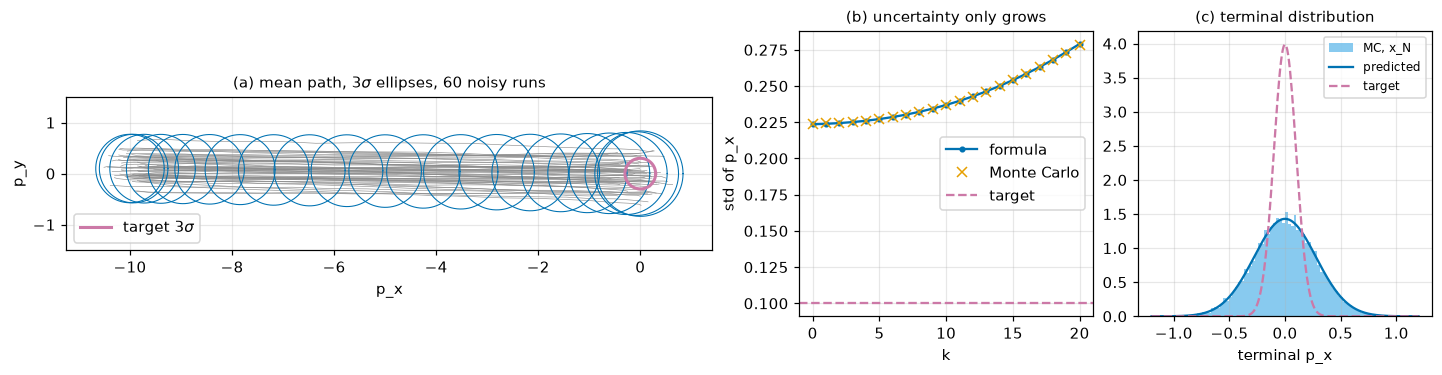

In [8]:
V_ol = np.linalg.pinv(E(N) @ B_cal) @ (mu_N - E(N) @ A_cal @ mu_0)
X_bar_ol = A_cal @ mu_0 + B_cal @ V_ol
Sigma_X_ol = A_cal @ Sigma_0 @ A_cal.T + D_cal @ D_cal.T
mus_ol = [E(k) @ X_bar_ol for k in range(N + 1)]
Sigmas_ol = [E(k) @ Sigma_X_ol @ E(k).T for k in range(N + 1)]

print("open-loop cost ||V||^2 =", round(V_ol @ V_ol, 4))
print("terminal mean          =", mus_ol[-1].round(6))
print("terminal pos. variance =", Sigmas_ol[-1][0, 0].round(4), " (target", Sigma_N[0, 0], ")")

xs_ol, *_ = simulate(V_ol, n_mc=20_000, seed=2)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), layout="constrained",
                         gridspec_kw={"width_ratios": [2.2, 1, 1]})
ax = axes[0]
for i in range(60):
    ax.plot([x[i, 0] for x in xs_ol], [x[i, 1] for x in xs_ol], color=GRAY, lw=0.4)
for k in range(N + 1):
    ax.plot(*ellipse_xy(mus_ol[k][:2], Sigmas_ol[k][:2, :2]), color=BLUE, lw=0.7)
ax.plot(*ellipse_xy(mu_N[:2], Sigma_N[:2, :2]), color=PURPLE, lw=2, label="target $3\\sigma$")
ax.set_aspect("equal"); ax.set_ylim(-1.5, 1.5); ax.legend(loc="lower left")
ax.set_xlabel("p_x"); ax.set_ylabel("p_y"); ax.set_title("(a) mean path, $3\\sigma$ ellipses, 60 noisy runs")

ax = axes[1]
ax.plot(range(N + 1), [np.sqrt(S[0, 0]) for S in Sigmas_ol], "o-", color=BLUE, ms=3, label="formula")
ax.plot(range(N + 1), [x[:, 0].std() for x in xs_ol], "x", color=ORANGE, label="Monte Carlo")
ax.axhline(np.sqrt(Sigma_N[0, 0]), color=PURPLE, ls="--", label="target")
ax.set_xlabel("k"); ax.set_ylabel("std of p_x"); ax.set_title("(b) uncertainty only grows"); ax.legend()

ax = axes[2]
ax.hist(xs_ol[-1][:, 0], bins=80, density=True, color=SKY, alpha=0.7, label="MC, x_N")
t = np.linspace(-1.2, 1.2, 300)
ax.plot(t, std_normal.pdf(t, mus_ol[-1][0], np.sqrt(Sigmas_ol[-1][0, 0])), color=BLUE, label="predicted")
ax.plot(t, std_normal.pdf(t, 0, np.sqrt(Sigma_N[0, 0])), color=PURPLE, ls="--", label="target")
ax.set_xlabel("terminal p_x"); ax.set_title("(c) terminal distribution"); ax.legend(fontsize=8)
plt.show()

**What it shows.**

- (a) The mean reaches the goal exactly, but the ellipses get wider along the way.
- (b) The formula and 20,000 simulated runs agree, and the standard deviation never decreases.
- (c) The final spread is about **8 times** too large in variance (0.078 vs 0.01). No choice of open-loop $V$ can fix this, because $V$ is not in the covariance equation.

The paper calls this *mean steering*. It is the baseline in all the experiments.

---
## 5. The Feedback Policy, and Why It Stays Convex (Theorem 1)

**Idea.** To shrink the cloud we must **react** to where the vehicle actually is. The natural choice is $u_k = v_k + K_k(x_k-\mu_k)$. The trouble is that the closed-loop error then evolves as $\tilde x_{k+1}=(A+BK_k)\tilde x_k + Dw_k$, and the covariance contains products such as $(A+BK_{k})(A+BK_{k-1})\cdots$. Products of decision variables make the problem **non-convex**, so it is hard to solve reliably.

**The paper's trick.** Feed back an *auxiliary* state that does not depend on the gains:

$$
\boxed{u_k = v_k + K_k y_k,\qquad y_{k+1} = A y_k + D w_k,\quad y_0 = x_0-\mu_0.}
$$

$y_k$ is "where the noise *alone* would have pushed the vehicle", with no correction. It can be computed online: since $D$ is invertible, $Dw_k = x_{k+1}-Ax_k-Bu_k$ from measured states.

**Derivation.** $y$ follows Eq. (1) with no control, so in lifted form $Y=\mathcal A y_0 + \mathcal D W$, with block-diagonal $K$ and $U=V+KY$. Substitute into Eq. (7), using $x_0=\mu_0+y_0$:

$$
X = \mathcal A\mu_0 + \underbrace{\mathcal A y_0 + \mathcal D W}_{Y} + \mathcal B V + \mathcal B K Y
= \underbrace{\mathcal A\mu_0+\mathcal BV}_{\bar X\ (\text{Eq. 15})} \;+\; \underbrace{(I+\mathcal BK)\,Y}_{\tilde X\ (\text{Eq. 16})}.
$$

Since $\mathbb E[Y]=0$ and $\operatorname{Cov}(Y)=\Sigma_Y=\mathcal A\Sigma_0\mathcal A^\top+\mathcal D\mathcal D^\top$:

$$
\bar X = \mathcal A\mu_0 + \mathcal BV,\qquad
\Sigma_X = (I+\mathcal BK)\,\Sigma_Y\,(I+\mathcal BK)^\top .
$$

> **$V$ moves only the mean and $K$ shapes only the covariance.** Inside the brackets everything is **linear** in $K$, so norms of $(I+\mathcal BK)\Sigma_Y^{1/2}$ are convex in $K$. That is the whole reason the problem stays convex.

**A square root we get for free.** $\Sigma_Y = L L^\top$ with $L=[\mathcal A\Sigma_0^{1/2},\ \mathcal D]$. Any factor works in the norms below, so we never need a matrix square root.

In [9]:
L = np.hstack([A_cal @ np.linalg.cholesky(Sigma_0), D_cal])
Sigma_Y = A_cal @ Sigma_0 @ A_cal.T + D_cal @ D_cal.T
print("L shape", L.shape, "| max |L L^T - Sigma_Y| =", f"{np.abs(L @ L.T - Sigma_Y).max():.1e}")

L shape (84, 84) | max |L L^T - Sigma_Y| = 8.3e-17


---
## 6. The Expected Cost (Eq. 17)

**Idea.** Minimize the expected value of $\sum_k x_k^\top Q_k x_k + u_k^\top R_k u_k$. Because the system is random, that expectation has a **mean part** and a **spread part**.

**Derivation.** For any random vector $z$ with mean $\bar z$ and covariance $\Sigma_z$:

$$
\mathbb E[z^\top M z] = \bar z^\top M\bar z + \operatorname{tr}(M\Sigma_z).
$$

Apply this to $X$ (mean $\bar X$, covariance $\Sigma_X$) and to $U=V+KY$ (mean $V$, covariance $K\Sigma_YK^\top$):

$$
J(V,K) = \underbrace{\bar X^\top\bar Q\bar X + V^\top\bar RV}_{J_{\text{mean}}(V)}
+ \underbrace{\operatorname{tr}\!\Big[\big((I+\mathcal BK)^\top\bar Q(I+\mathcal BK)+K^\top\bar RK\big)\Sigma_Y\Big]}_{J_{\text{cov}}(K)} .
$$

With $\Sigma_Y=LL^\top$, each trace becomes a squared Frobenius norm, $\operatorname{tr}(K^\top \bar R K LL^\top)=\|\bar R^{1/2}KL\|_F^2$, which is convex and easy for the solver.

**Check.** Pick an arbitrary block-diagonal $K$ and compare three numbers: the trace formula, the Frobenius form, and a Monte Carlo average of $(KY)^\top(KY)$.

In [10]:
g = np.random.default_rng(5)
K_ks_rand = [0.3 * g.normal(size=(nu, nx)) for _ in range(N)]
K_rand = np.zeros((N * nu, (N + 1) * nx))
for k in range(N):
    K_rand[k * nu:(k + 1) * nu, k * nx:(k + 1) * nx] = K_ks_rand[k]

trace_form = np.trace(K_rand.T @ K_rand @ Sigma_Y)
frob_form = np.sum((K_rand @ L) ** 2)
_, ys, _, _ = simulate(np.zeros(N * nu), K_ks_rand, n_mc=50_000, seed=6)
Y = np.hstack(ys)                                    # (n_mc, (N+1) nx), same stacking as X
mc_form = np.mean(np.sum((Y @ K_rand.T) ** 2, axis=1))
print(f"tr(K^T K Sigma_Y) = {trace_form:.4f}   ||K L||_F^2 = {frob_form:.4f}   Monte Carlo = {mc_form:.4f}")

tr(K^T K Sigma_Y) = 0.3396   ||K L||_F^2 = 0.3396   Monte Carlo = 0.3401


---
## 7. Terminal Constraints, and the First Optimal Controller (Eqs. 18–19)

**Mean.** $E_N\bar X = \mu_N$, a linear equation in $V$.

**Covariance.** We would like $E_N\Sigma_XE_N^\top=\Sigma_N$, but an equality of a quadratic expression is **not convex**. The paper relaxes it to "no larger than the target":

$$
E_N\Sigma_XE_N^\top \preceq \Sigma_N
\quad\Longleftrightarrow\quad
\Sigma_N - E_N\Sigma_XE_N^\top \text{ is positive semidefinite}.
$$

**What $\preceq$ means geometrically.** $\Sigma_a\preceq\Sigma_b$ means the variance in **every** direction is smaller, so the ellipse of $\Sigma_a$ fits **inside** the ellipse of $\Sigma_b$. A smaller total size (trace) is not enough:

target Sigma_N                       trace = 0.0200   min eig(Sigma_N - Sigma) = +0.0000
inside: Sigma <= Sigma_N             trace = 0.0100   min eig(Sigma_N - Sigma) = +0.0028
smaller trace, but NOT <= Sigma_N    trace = 0.0150   min eig(Sigma_N - Sigma) = -0.0030


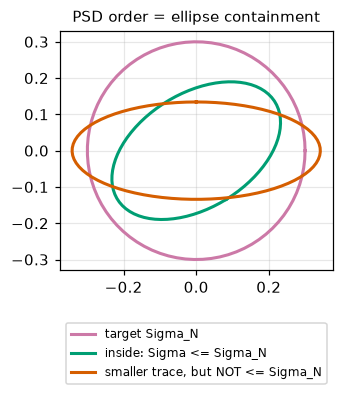

In [11]:
fig, ax = plt.subplots(figsize=(4.2, 3.3), layout="constrained")
S_target = np.diag([0.01, 0.01])
S_inside = np.array([[0.006, 0.002], [0.002, 0.004]])
S_not = np.diag([0.013, 0.002])           # smaller trace, but sticks out in x
for S, c, lab in [(S_target, PURPLE, "target Sigma_N"),
                  (S_inside, GREEN, "inside: Sigma <= Sigma_N"),
                  (S_not, VERMILLION, "smaller trace, but NOT <= Sigma_N")]:
    ax.plot(*ellipse_xy(np.zeros(2), S), color=c, lw=2, label=lab)
    print(f"{lab:36s} trace = {np.trace(S):.4f}   min eig(Sigma_N - Sigma) = {np.linalg.eigvalsh(S_target - S).min():+.4f}")
ax.set_aspect("equal"); ax.legend(fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.5))
ax.set_title("PSD order = ellipse containment"); plt.show()

**Making it a norm (Eq. 19).** Write $G=E_N(I+\mathcal BK)L$, so that $E_N\Sigma_XE_N^\top = GG^\top$. Multiplying both sides by $\Sigma_N^{-1/2}$:

$$
GG^\top \preceq \Sigma_N
\iff \big(\Sigma_N^{-1/2}G\big)\big(\Sigma_N^{-1/2}G\big)^\top \preceq I
\iff \boxed{\big\|\Sigma_N^{-1/2}E_N(I+\mathcal BK)L\big\|_2 \le 1}
$$

The spectral norm (largest singular value) of something **affine in $K$** is convex, so this is a valid convex constraint (a semidefinite one).

**Problem 2 (no obstacles yet).** Minimize $J_{\text{mean}}+J_{\text{cov}}$ subject to the terminal mean, the terminal covariance and the bounds. The builder below is reused for the rest of the notebook: later sections add constraints on top of what it returns.

In [12]:
def build_problem(feedback=True, terminal_cov="sdp"):
    """Variables, expressions and basic constraints of Problem 2.

    Args:
        feedback: False gives mean steering (K = 0, no covariance constraint).
        terminal_cov: "sdp" adds Eq. (19) as a spectral norm; "cuts" leaves it
            out (Section 9 enforces it with cutting planes instead).

    Returns:
        dict with variables V, K, block list K_list, expressions X_bar, IBK_L,
        J_mean, J_cov, M_term (matrix of Eq. 19) and the constraint list cons.
    """
    nX = (N + 1) * nx
    V = cp.Variable(N * nu)
    if feedback:
        K_list = [cp.Variable((nu, nx)) for _ in range(N)]
        Z = np.zeros((nu, nx))
        K = cp.bmat([[K_list[k] if j == k else Z for j in range(N + 1)] for k in range(N)])
    else:
        K_list, K = [], np.zeros((N * nu, nX))

    X_bar = A_cal @ mu_0 + B_cal @ V                     # Eq. (15)
    IBK_L = (np.eye(nX) + B_cal @ K) @ L                 # Sigma_X = IBK_L IBK_L^T
    Q_bar, R_bar = np.kron(np.eye(N + 1), Q_k), np.kron(np.eye(N), R_k)
    J_mean = cp.quad_form(X_bar, Q_bar) + cp.quad_form(V, R_bar)
    J_cov = cp.sum_squares(np.sqrt(Q_bar) @ IBK_L) + cp.sum_squares(np.sqrt(R_bar) @ K @ L)  # Eq. (17)

    cons = [E(N) @ X_bar == mu_N, cp.abs(V) <= V_MAX]  # Eq. (18a), bounds
    M_term = None
    if feedback:
        M_term = np.diag(1 / np.sqrt(np.diag(Sigma_N))) @ E(N) @ IBK_L
        if terminal_cov == "sdp":
            cons.append(cp.sigma_max(M_term) <= 1)       # Eq. (19)
        cons += [cp.abs(Kk) <= K_MAX for Kk in K_list]
    return dict(V=V, K=K, K_list=K_list, X_bar=X_bar, IBK_L=IBK_L,
                J_mean=J_mean, J_cov=J_cov, M_term=M_term, cons=cons)


def numeric_solution(P):
    """Mean/covariance trajectories and gains of a solved problem."""
    K_val = P["K"].value if P["K_list"] else P["K"]
    IBK_L = (np.eye((N + 1) * nx) + B_cal @ K_val) @ L
    Sigma_X = IBK_L @ IBK_L.T
    X_bar = A_cal @ mu_0 + B_cal @ P["V"].value
    mus = [E(k) @ X_bar for k in range(N + 1)]
    Sigmas = [E(k) @ Sigma_X @ E(k).T for k in range(N + 1)]
    K_ks = [K_val[k * nu:(k + 1) * nu, k * nx:(k + 1) * nx] for k in range(N)]
    return mus, Sigmas, K_ks

In [13]:
free = {}
for name, fb in [("mean steering", False), ("covariance steering", True)]:
    P = build_problem(feedback=fb)
    prob = cp.Problem(cp.Minimize(P["J_mean"] + P["J_cov"]), P["cons"])
    prob.solve(solver=SOLVER)
    mus, Sigmas, K_ks = numeric_solution(P)
    xs, ys, _, cost = simulate(P["V"].value, K_ks, n_mc=20_000, seed=1)
    free[name] = dict(mus=mus, Sigmas=Sigmas, K_ks=K_ks, xs=xs, ys=ys)
    print(f"{name:20s} J = {prob.value:8.4f} (mean {P['J_mean'].value:.4f} + cov {float(P['J_cov'].value):.4f})"
          f" | MC cost {cost.mean():.4f}"
          f" | max eig(Sigma_xN - Sigma_N) = {np.linalg.eigvalsh(Sigmas[-1] - Sigma_N).max():+.1e}"
          f" | MC var p_x(N) = {xs[-1][:, 0].var():.4f}")

fs = free["covariance steering"]
k = N // 2
print(f"\ny_k vs x_k - mu_k at k={k}: max difference = "
      f"{np.abs(fs['ys'][k] - (fs['xs'][k] - fs['mus'][k])).max():.3f}  -> y is NOT the tracking error")

mean steering        J =  93.9944 (mean 93.9944 + cov 0.0000) | MC cost 93.9944 | max eig(Sigma_xN - Sigma_N) = +6.9e-02 | MC var p_x(N) = 0.0762


covariance steering  J =  94.0323 (mean 93.9944 + cov 0.0379) | MC cost 94.0490 | max eig(Sigma_xN - Sigma_N) = -5.6e-09 | MC var p_x(N) = 0.0099

y_k vs x_k - mu_k at k=10: max difference = 0.322  -> y is NOT the tracking error


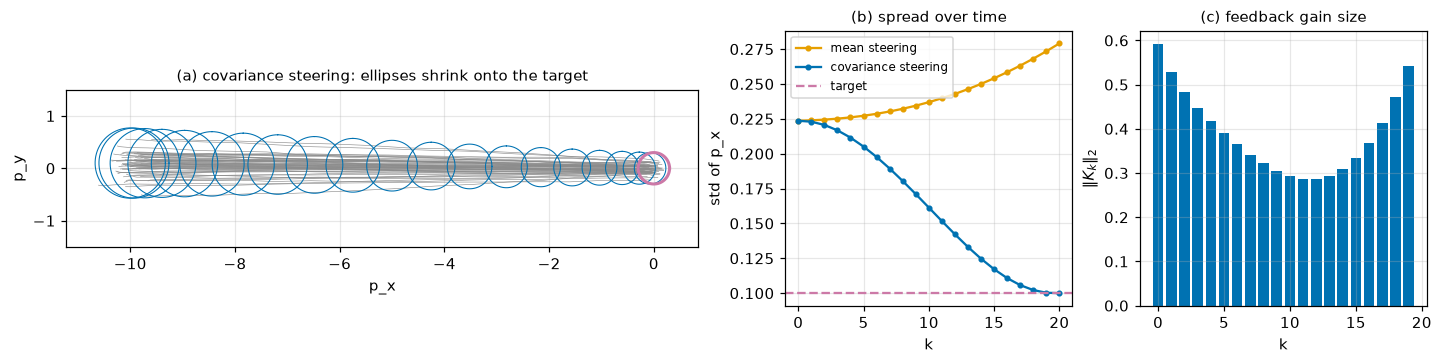

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), layout="constrained",
                         gridspec_kw={"width_ratios": [2.2, 1, 1]})
ax = axes[0]
fs = free["covariance steering"]
for i in range(60):
    ax.plot([x[i, 0] for x in fs["xs"]], [x[i, 1] for x in fs["xs"]], color=GRAY, lw=0.4)
for k in range(N + 1):
    ax.plot(*ellipse_xy(fs["mus"][k][:2], fs["Sigmas"][k][:2, :2]), color=BLUE, lw=0.7)
ax.plot(*ellipse_xy(mu_N[:2], Sigma_N[:2, :2]), color=PURPLE, lw=2)
ax.set_aspect("equal"); ax.set_ylim(-1.5, 1.5); ax.set_xlabel("p_x"); ax.set_ylabel("p_y")
ax.set_title("(a) covariance steering: ellipses shrink onto the target")

ax = axes[1]
for name, c in [("mean steering", ORANGE), ("covariance steering", BLUE)]:
    ax.plot([np.sqrt(S[0, 0]) for S in free[name]["Sigmas"]], "o-", ms=3, color=c, label=name)
ax.axhline(np.sqrt(Sigma_N[0, 0]), color=PURPLE, ls="--", label="target")
ax.set_xlabel("k"); ax.set_ylabel("std of p_x"); ax.legend(fontsize=8); ax.set_title("(b) spread over time")

ax = axes[2]
ax.bar(range(N), [np.linalg.norm(Kk, 2) for Kk in fs["K_ks"]], color=BLUE)
ax.set_xlabel("k"); ax.set_ylabel("$\\|K_k\\|_2$"); ax.set_title("(c) feedback gain size")
plt.show()

**What it shows.**

- With feedback, the terminal covariance constraint is met **exactly**: the largest eigenvalue of $\Sigma_{x_N}-\Sigma_N$ is about 0, so the constraint is *active*. Simulation gives a terminal variance of 0.0099.
- The extra cost of feedback is tiny: $J_\text{cov}\approx 0.04$ against $J_\text{mean}\approx 94$. **Without obstacles, shrinking uncertainty is almost free.** The interesting trade-off only appears when obstacles demand a small spread *partway along* the path (§10–11).
- The simulation confirms $y_k\neq x_k-\mu_k$. The policy really does feed back the auxiliary state.

---
## 8. Chance Constraints: Probabilistic Safety (Eq. 20)

**Idea.** The noise is Gaussian, so it is unbounded: no controller can *guarantee* that $x_k$ stays in a region. Instead we require each constraint to fail with probability at most $\epsilon$.

**Derivation.** Take one half-space $a^\top x_k\le b$. The scalar $a^\top x_k$ is Gaussian with mean $a^\top\mu_k$ and standard deviation $\sigma_a=\sqrt{a^\top\Sigma_k a}$. Then

$$
\Pr(a^\top x_k > b) = 1-\Phi\!\left(\frac{b-a^\top\mu_k}{\sigma_a}\right) \le \epsilon
\iff
\boxed{a^\top\mu_k + \Phi^{-1}(1-\epsilon)\,\sigma_a \le b}
$$

where $\Phi$ is the standard normal CDF. In words: **keep the mean at least $\Phi^{-1}(1-\epsilon)$ standard deviations away from the wall.** For $\epsilon=10^{-3}$ that is 3.09 standard deviations.

Using the factor $L$, $\sigma_a = \|a^\top E_k(I+\mathcal BK)L\|_2$, a **norm of something affine in $K$**. The constraint is therefore a second-order cone (SOC) constraint, and the problem stays convex.

Phi^-1(1 - 0.001) = 3.0902


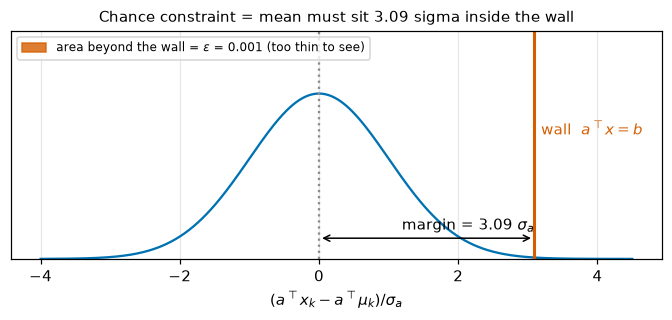

In [15]:
PHI_INV = std_normal.ppf(1 - eps)
print(f"Phi^-1(1 - {eps}) = {PHI_INV:.4f}")

fig, ax = plt.subplots(figsize=(6, 2.8), layout="constrained")
t = np.linspace(-4, 4.5, 400)
ax.plot(t, std_normal.pdf(t), color=BLUE)
ax.fill_between(t[t > PHI_INV], std_normal.pdf(t[t > PHI_INV]), color=VERMILLION, alpha=0.8,
                label=f"area beyond the wall = $\\epsilon$ = {eps:g} (too thin to see)")
ax.axvline(0, color=GRAY, ls=":"); ax.axvline(PHI_INV, color=VERMILLION, lw=2)
ax.annotate("", xy=(PHI_INV, 0.05), xytext=(0, 0.05), arrowprops=dict(arrowstyle="<->"))
ax.text(PHI_INV / 2 + 0.6, 0.07, f"margin = {PHI_INV:.2f} $\\sigma_a$", ha="center")
ax.text(PHI_INV + 0.1, 0.30, "wall  $a^\\top x = b$", color=VERMILLION)
ax.set_ylim(0, 0.55)
ax.set_xlabel("$(a^\\top x_k - a^\\top \\mu_k)/\\sigma_a$"); ax.set_yticks([]); ax.legend(loc="upper left", fontsize=8)
ax.set_title("Chance constraint = mean must sit 3.09 sigma inside the wall"); plt.show()

**A test you can see.** Put a narrow **gate** $|p_y|\le 0.3$ at steps $k=8,\dots,12$. This gate is our own test, not in the paper. Fitting through it needs $3.09\,\sigma_y\le 0.3$, i.e. $\sigma_y\le 0.097$, but open loop has $\sigma_y\approx 0.24$ there. We expect mean steering to be infeasible and covariance steering to make it. Then we count simulated violations.

In [16]:
def pos_std(P, k, i):
    '''sigma of position coordinate i (0 = x, 1 = y) at step k: the norm in Eq. (20).'''
    return cp.norm(P["IBK_L"][k * nx + i, :])


GATE_K, GATE_HALF = range(8, 13), 0.3
for name, fb in [("mean steering", False), ("covariance steering", True)]:
    P = build_problem(feedback=fb)
    cons = list(P["cons"])
    for k in GATE_K:
        p_y, s = P["X_bar"][k * nx + 1], PHI_INV * pos_std(P, k, 1)
        cons += [p_y + s <= GATE_HALF, -p_y + s <= GATE_HALF]   # two faces, Eq. (20)
    prob = cp.Problem(cp.Minimize(P["J_mean"] + P["J_cov"]), cons)
    prob.solve(solver=SOLVER)
    print(f"{name}: {prob.status}")
gate = P
mus_g, Sigmas_g, K_g = numeric_solution(gate)
xs_g, *_ = simulate(gate["V"].value, K_g, n_mc=400_000, seed=4)
print(f"\n k  mu_y    3.09 sigma_y  constraint used?   MC Pr(p_y > 0.3)  (limit {eps})")
for k in GATE_K:
    slack = abs(mus_g[k][1]) + PHI_INV * np.sqrt(Sigmas_g[k][1, 1]) - GATE_HALF
    print(f"{k:2d}  {mus_g[k][1]:+.3f}   {PHI_INV * np.sqrt(Sigmas_g[k][1, 1]):.3f}       "
          f"{'ACTIVE' if slack > -1e-6 else 'slack ':6s}            {np.mean(xs_g[k][:, 1] > GATE_HALF):.5f}")
print(f"(Monte Carlo standard error at p = 1e-3 with 400k runs: {np.sqrt(eps / 4e5):.1e})")

mean steering: infeasible


covariance steering: optimal



 k  mu_y    3.09 sigma_y  constraint used?   MC Pr(p_y > 0.3)  (limit 0.001)
 8  +0.045   0.255       ACTIVE            0.00102
 9  +0.037   0.201       slack             0.00003
10  +0.030   0.164       slack             0.00000
11  +0.023   0.145       slack             0.00000
12  +0.018   0.145       slack             0.00000
(Monte Carlo standard error at p = 1e-3 with 400k runs: 5.0e-05)


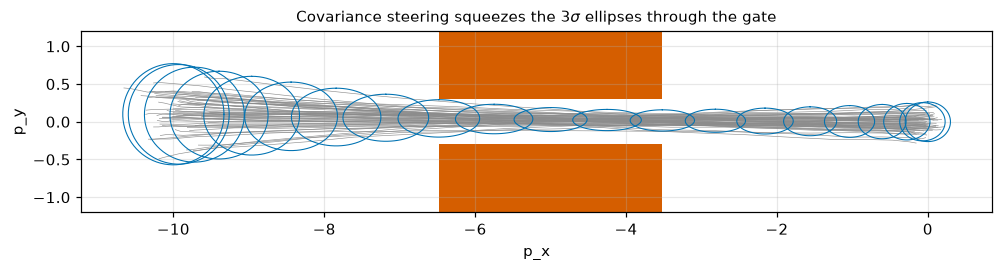

In [17]:
fig, ax = plt.subplots(figsize=(9, 2.8), layout="constrained")
x_lo, x_hi = mus_g[GATE_K[0]][0], mus_g[GATE_K[-1]][0]
for yb in (GATE_HALF, -GATE_HALF):
    ax.fill_between([x_lo, x_hi], yb, np.sign(yb) * 1.3, color=VERMILLION, lw=0)
for i in range(60):
    ax.plot([x[i, 0] for x in xs_g], [x[i, 1] for x in xs_g], color=GRAY, lw=0.4)
for k in range(N + 1):
    ax.plot(*ellipse_xy(mus_g[k][:2], Sigmas_g[k][:2, :2]), color=BLUE, lw=0.7)
ax.set_aspect("equal"); ax.set_ylim(-1.2, 1.2); ax.set_xlabel("p_x"); ax.set_ylabel("p_y")
ax.set_title("Covariance steering squeezes the $3\\sigma$ ellipses through the gate"); plt.show()

**What it shows.** Mean steering is **infeasible**. Covariance steering passes, with the constraint active at the first gate step. There the simulated violation rate is about 0.001, exactly the $\epsilon$ we asked for. The other steps have slack and essentially zero violations. The formula is neither loose nor optimistic: it is tight where it binds.

---
## 9. Obstacles: Mixed-Integer Region Selection (Eqs. 22–25, Algorithm 1)

**Idea.** The free space around obstacles is **not convex**: you can go above *or* below an obstacle, and averaging the two is a collision. The paper's approach:

1. **Cover the free space with overlapping convex boxes** $\mathcal R_r$ (Eq. 22–23).
2. Use **binary variables** to choose a box for each time step.
3. Inside the chosen box, use the convex chance constraints of §8.

**Region selection.** $M_{r,k}\in\{0,1\}$, where $M_{r,k}=1$ means **both** $x_k$ and $x_{k+1}$ lie in box $r$ (with chance constraints). Exactly one box is chosen per step (Eq. 24):

$$
\sum_r M_{r,k} = 1 .
$$

*Why both endpoints?* A box is convex, so if both ends of the segment $x_k\to x_{k+1}$ are inside it, the whole straight segment is inside. That stops the path from cutting a corner between samples.

**Turning "if $M_{r,k}=1$ then (25)" into math: big-M.**

$$
a^\top\mu_\kappa + 3.09\,\sigma_a(\kappa) - b \;\le\; \text{BIG}_M\,(1-M_{r,k}),\qquad \kappa\in\{k,k+1\}.
$$

If $M_{r,k}=1$ the right side is 0 and the chance constraint is enforced. If $M_{r,k}=0$ the right side is huge and the constraint is switched off. BIG_M must be larger than any value the left side can take. We always enforce the outer walls of the map ($x\in[-12,2]$, $y\in[-5,5]$), which bounds every left side by $14+14=28$, so BIG_M = 30 is safe.

**A shortcut.** All box faces here are axis-aligned ($a=\pm e_x$ or $\pm e_y$), so we only need $\sigma_x(k)$ and $\sigma_y(k)$: two SOC constraints per step.

**The geometry** is read off the paper's Figs. 2, 3 and 6 by eye. It is *reconstructed*, not given.

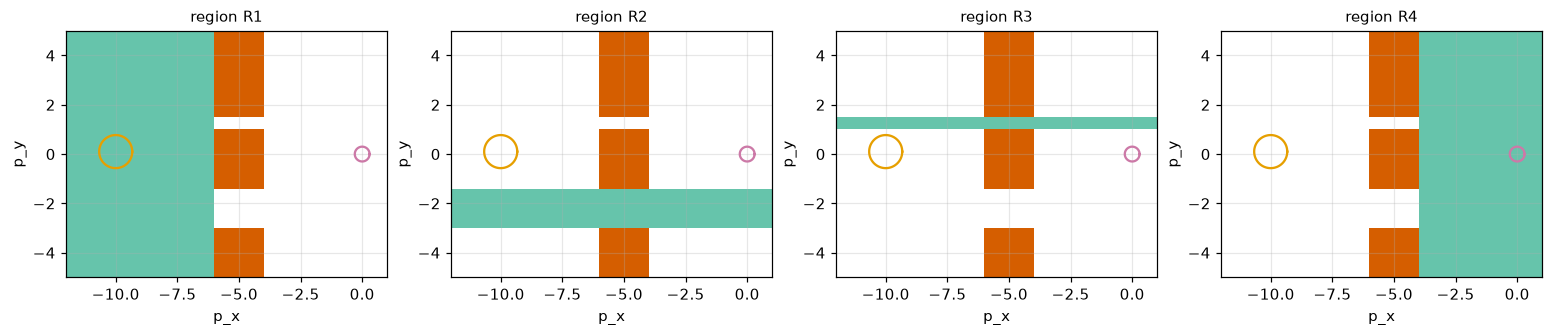

In [18]:
WORKSPACE = (-12.0, 2.0, -5.0, 5.0)        # (x_min, x_max, y_min, y_max)
BIG_M = 30.0


def double_slit(top_gap=0.5):
    """Double-slit world (RECONSTRUCTED from paper Figs. 2, 3, 6).

    Args:
        top_gap: width of the upper slit (0.5 in Fig. 2).

    Returns:
        dict with obstacle boxes, free-space regions, and top_gap.
    """
    top = 1.0 + top_gap
    obstacles = [(-6, -4, top, 5), (-6, -4, -1.4, 1.0), (-6, -4, -5, -3)]
    regions = [(-12, -6, -5, 5),       # R1: left of the wall
               (-12, 2, -3, -1.4),     # R2: band through the lower slit
               (-12, 2, 1.0, top),     # R3: band through the upper slit
               (-4, 2, -5, 5)]         # R4: right of the wall
    return dict(obstacles=obstacles, regions=regions, top_gap=top_gap)


def box_faces(box):
    """Faces of an axis-aligned box as (coordinate i, sign, b): sign * p_i <= b."""
    x0, x1, y0, y1 = box
    return [(0, -1, -x0), (0, +1, x1), (1, -1, -y0), (1, +1, y1)]


def draw_world(ax, geom):
    """Obstacles and axes of the double-slit map."""
    for (x0, x1, y0, y1) in geom["obstacles"]:
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, color=VERMILLION, lw=0))
    ax.set_xlim(-12, 1); ax.set_ylim(-5, 5); ax.set_aspect("equal")
    ax.set_xlabel("p_x"); ax.set_ylabel("p_y")


geom = double_slit(0.5)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), layout="constrained")
for r, (ax, box) in enumerate(zip(axes, geom["regions"])):
    x0, x1, y0, y1 = box
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, color=GREEN, alpha=0.6, lw=0))
    draw_world(ax, geom)
    ax.plot(*ellipse_xy(mu_0[:2], Sigma_0[:2, :2]), color=ORANGE, lw=1.5)
    ax.plot(*ellipse_xy(mu_N[:2], Sigma_N[:2, :2]), color=PURPLE, lw=1.5)
    ax.set_title(f"region R{r + 1}")
plt.show()

The four green boxes overlap and together cover all the free space (paper Fig. 3). A path from the orange start to the purple goal must go R1 → (R2 *or* R3) → R4. **Choosing R2 or R3 is choosing the lower or upper slit**, and the solver makes that choice through the binaries.

### A solver obstacle, and how we get around it

MOSEK, the paper's solver, handles **mixed-integer SOCPs** but **not** mixed-integer *semidefinite* programs, and the terminal constraint (19) is semidefinite. (The paper used YALMIP, which runs its own branch-and-bound in that case.) We use an exact **cutting-plane** method instead.

**Step 1: the spectral norm as many SOCs.** The spectral norm is the largest stretch in any direction:

$$
\|G\|_2\le 1 \iff \|G^\top z\|_2 \le 1\ \ \text{for every unit vector } z\in\mathbb R^4 .
$$

Each fixed $z$ gives an SOC constraint. Enforcing a finite set of directions $z$ is a **relaxation**: fewer constraints, so its optimum is a **lower bound** (LB) on the true optimum.

**Step 2: an upper bound.** Take the route (the binaries) the relaxation chose, fix it, and solve the problem with the **exact** constraint (19). With the route fixed there are no integers left, so this is an ordinary convex SDP. Its optimum is achievable, so it is an **upper bound** (UB).

**Step 3: stop or refine.** If $(\text{UB}-\text{LB})/\text{UB}\le 10^{-4}$, the fixed-route solution is **certified optimal**. Otherwise add the most violated direction $z$ (the top singular vector) and repeat.

In [19]:
def region_constraints(P, geom, M, feedback, forbid=()):
    """Workspace walls, region selection (Eq. 24) and big-M chance constraints (Eq. 25).

    Args:
        P: problem dict from build_problem.
        geom: map from double_slit.
        M: boolean cp.Variable (NR x N) for the real problem, or a fixed 0/1
            array (route fixed -> convex problem).
        feedback: whether K is a decision variable.
        forbid: region indices that may not be used (to force a route).

    Returns:
        list of constraints.
    """
    pos = []
    for i in range(2):                                   # mean positions, k = 0..N
        S = np.zeros((N + 1, (N + 1) * nx))
        S[np.arange(N + 1), np.arange(N + 1) * nx + i] = 1
        pos.append(S @ P["X_bar"])
    cons = []
    if feedback:                                         # s[i, k] >= 3.09 sigma_i(k)
        s = cp.Variable((2, N + 1))
        for i in range(2):
            rows = [k * nx + i for k in range(N + 1)]
            cons.append(s[i] >= PHI_INV * cp.norm(P["IBK_L"][rows, :], 2, axis=1))
        sd = [s[0], s[1]]
    else:                                                # K = 0: sigma is a number
        sd = [PHI_INV * np.linalg.norm(P["IBK_L"][[k * nx + i for k in range(N + 1)]], axis=1)
              for i in range(2)]
    for i, sgn, b in box_faces(WORKSPACE):               # walls always on -> BIG_M valid
        cons.append(sgn * pos[i] + sd[i] <= b)

    is_var = isinstance(M, cp.Variable)
    if is_var:
        cons.append(cp.sum(M, axis=0) == 1)              # Eq. (24)
        cons += [M[r] == 0 for r in forbid]
    for r, box in enumerate(geom["regions"]):
        if not is_var and not M[r].any():
            continue
        for i, sgn, b in box_faces(box):
            for sl in (slice(0, N), slice(1, N + 1)):    # x_k and x_{k+1}
                cons.append(sgn * pos[i][sl] + sd[i][sl] - b <= BIG_M * (1 - M[r]))  # Eq. (25)
    return cons


def solve_algorithm1(geom, feedback=True, forbid=(), tol=1e-4, max_iter=20, verbose=True):
    """Algorithm 1 with cutting planes on Eq. (19) and an LB/UB optimality certificate.

    Returns:
        dict of numeric results, or None if infeasible.
    """
    t0 = time.time()
    P = build_problem(feedback=feedback, terminal_cov="cuts")
    NR = len(geom["regions"])
    M = cp.Variable((NR, N), boolean=True)
    cons = P["cons"] + region_constraints(P, geom, M, feedback, forbid)
    J = P["J_mean"] + P["J_cov"]
    I4 = np.eye(nx)
    zs = ([I4[i] for i in range(nx)]
          + [(I4[i] + sg * I4[j]) / np.sqrt(2) for i in range(nx) for j in range(i + 1, nx) for sg in (1, -1)]
          if feedback else [])
    for it in range(1, max_iter + 1):
        prob = cp.Problem(cp.Minimize(J), cons + [cp.norm(z @ P["M_term"]) <= 1 for z in zs])
        prob.solve(solver=cp.MOSEK, mosek_params={"MSK_DPAR_MIO_TOL_REL_GAP": 1e-6})
        if prob.status not in ("optimal", "optimal_inaccurate"):
            print("  infeasible"); return None
        M_val, LB = np.round(M.value).astype(int), prob.value
        if not feedback:                                 # no Eq. (19): MI problem is exact
            final, UB = P, LB
            break
        P2 = build_problem(feedback=True, terminal_cov="sdp")       # route fixed, exact (19)
        prob2 = cp.Problem(cp.Minimize(P2["J_mean"] + P2["J_cov"]),
                           P2["cons"] + region_constraints(P2, geom, M_val, True))
        prob2.solve(solver=cp.MOSEK)
        UB = prob2.value if prob2.status == "optimal" else np.inf
        gap = (UB - LB) / UB if np.isfinite(UB) else np.inf
        if verbose:
            print(f"  iteration {it}: {len(zs)} cut directions, LB = {LB:.4f}, UB = {UB:.4f}, gap = {gap:.1e}")
        if gap <= tol:
            final = P2
            break
        G = np.diag(1 / np.sqrt(np.diag(Sigma_N))) @ E(N) @ (np.eye((N + 1) * nx) + B_cal @ P["K"].value) @ L
        zs.append(np.linalg.svd(G)[0][:, 0])              # most violated direction
    mus, Sigmas, K_ks = numeric_solution(final)
    used = [r for r in range(NR) if M_val[r].any()]
    return dict(J=float(LB if not feedback else UB), J_mean=float(final["J_mean"].value),
                J_cov=float(final["J_cov"].value) if feedback else 0.0,
                V=final["V"].value.copy(), K_ks=K_ks, mus=mus, Sigmas=Sigmas, M=M_val,
                route="upper" if 2 in used else "lower", time=time.time() - t0)


def draw_solution(ax, geom, res, n_paths=60):
    """Map, 60 simulated runs, 3-sigma ellipses and mean path of a solution."""
    draw_world(ax, geom)
    xs, *_ = simulate(res["V"], res["K_ks"], n_mc=n_paths, seed=7)
    for i in range(n_paths):
        ax.plot([x[i, 0] for x in xs], [x[i, 1] for x in xs], color=GRAY, lw=0.4)
    for k in range(N + 1):
        ax.plot(*ellipse_xy(res["mus"][k][:2], res["Sigmas"][k][:2, :2]),
                color=ORANGE if k == 0 else BLUE, lw=1.5 if k == 0 else 0.7)
    ax.plot(*np.array(res["mus"])[:, :2].T, ".-", color=BLUE, lw=1.5)
    ax.plot(*ellipse_xy(mu_N[:2], Sigma_N[:2, :2]), color=PURPLE, lw=1.5)


def region_sequence(res):
    """Chosen region per step pair, e.g. '11112222...' (1-based)."""
    return "".join(str(int(np.argmax(res["M"][:, k])) + 1) for k in range(N))

---
## 10. Experiment 1: The Double Slit (Paper Fig. 2)

The upper slit is narrow (0.5) but on the direct line to the goal. The lower slit is wider (1.6) but a detour. **Which route does each planner pick?**

mean steering:


  -> lower slit, J = 201.683 (mean 201.683 + cov 0.000), 1 s, regions per step: 11111111222244444444
covariance steering:


  iteration 1: 16 cut directions, LB = 116.4226, UB = 116.4226, gap = 5.4e-10
  -> upper slit, J = 116.423 (mean 115.993 + cov 0.430), 49 s, regions per step: 11111111333344444444


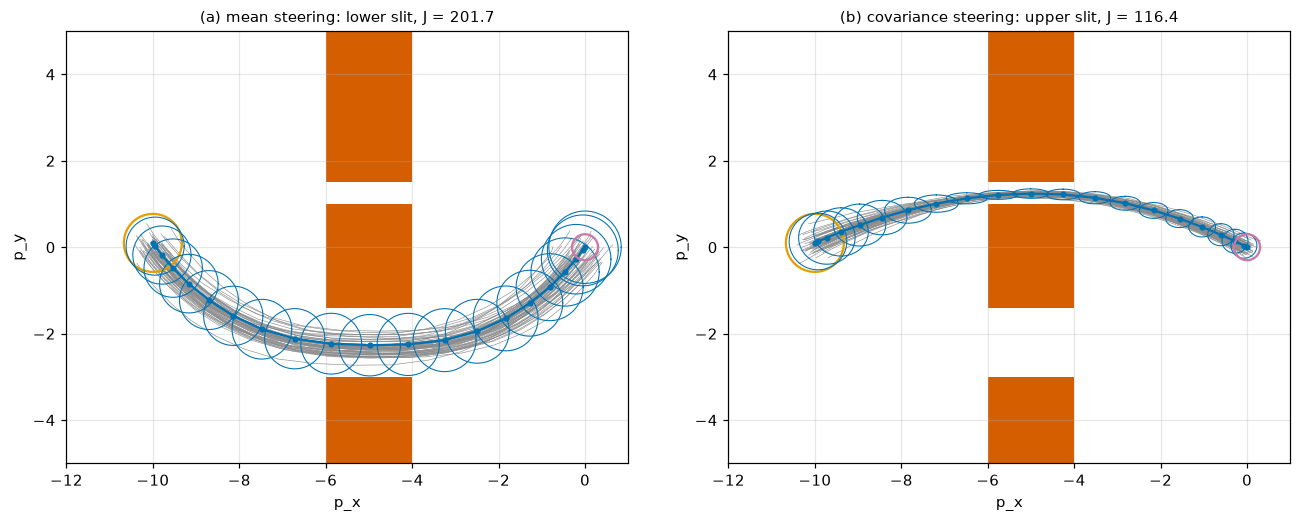

In [20]:
geom1 = double_slit(0.5)
exp1 = {}
for name, fb in [("mean steering", False), ("covariance steering", True)]:
    print(f"{name}:")
    exp1[name] = res = solve_algorithm1(geom1, feedback=fb)
    print(f"  -> {res['route']} slit, J = {res['J']:.3f} (mean {res['J_mean']:.3f} + cov {res['J_cov']:.3f}), "
          f"{res['time']:.0f} s, regions per step: {region_sequence(res)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
for ax, (name, res), tag in zip(axes, exp1.items(), "ab"):
    draw_solution(ax, geom1, res)
    ax.set_title(f"({tag}) {name}: {res['route']} slit, J = {res['J']:.1f}")
plt.show()

**What it shows (matches paper Fig. 2).**

- **(a) Mean steering** cannot shrink its ellipses. Its $3\sigma$ margin is about 0.75 on each side, too wide for the 0.5 upper slit, so it must **detour** through the lower slit. The detour costs J ≈ 202.
- **(b) Covariance steering** squeezes the ellipses before the wall, passes the **narrow upper slit**, and lets them grow again afterwards (to the target size). J ≈ 116, **42% cheaper**.
- Of that 116, only about 0.4 is the covariance cost. Feedback is cheap in itself; **its value is that it unlocks a much cheaper mean path.**
- The region sequence `1111111133334444…` reads as: R1 for 8 steps, through the upper band R3 for 4, then R4.
- The relaxation was already exact on the first iteration (gap below $10^{-9}$).

---
## 11. Experiment 2: Narrower Slit, and Why the Route Switches (Paper Fig. 4)

Narrow the upper slit from 0.5 to 0.2 (read off the paper's Fig. 4a by eye).

covariance steering:


  iteration 1: 16 cut directions, LB = 139.0831, UB = 139.0844, gap = 9.5e-06
  -> lower slit, J = 139.084 (mean 138.336 + cov 0.748), 29 s, regions per step: 11111111122244444444
mean steering (route can't change: the upper slit was already too narrow):


  -> lower slit, J = 201.683


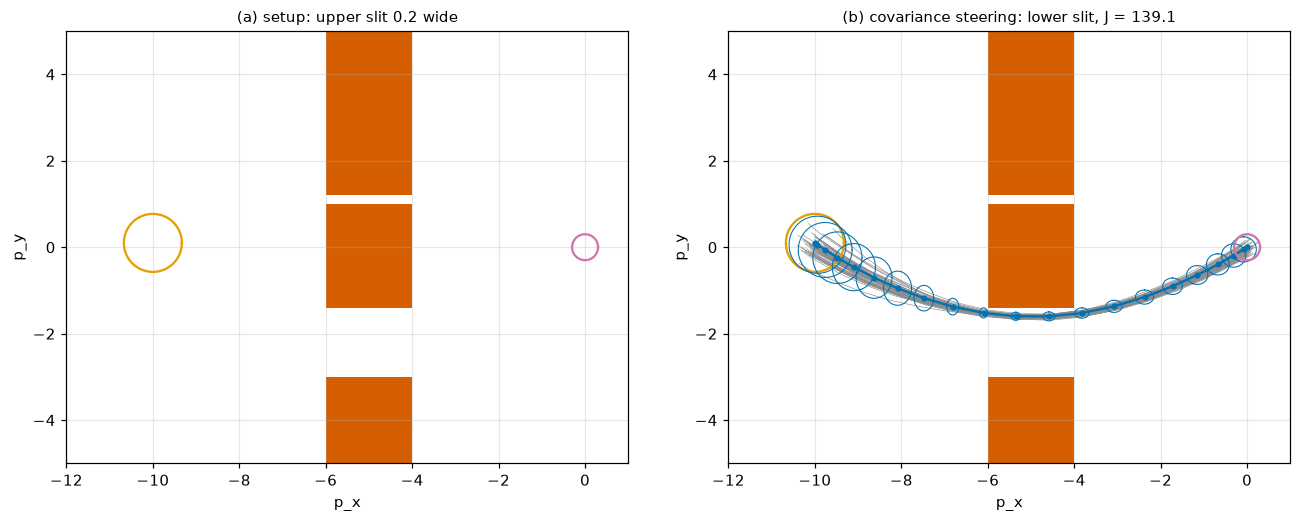

In [21]:
geom2 = double_slit(0.2)
print("covariance steering:")
exp2 = solve_algorithm1(geom2, feedback=True)
print(f"  -> {exp2['route']} slit, J = {exp2['J']:.3f} (mean {exp2['J_mean']:.3f} + cov {exp2['J_cov']:.3f}), "
      f"{exp2['time']:.0f} s, regions per step: {region_sequence(exp2)}")
print("mean steering (route can't change: the upper slit was already too narrow):")
exp2_mean = solve_algorithm1(geom2, feedback=False)
print(f"  -> {exp2_mean['route']} slit, J = {exp2_mean['J']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
draw_world(axes[0], geom2)
axes[0].plot(*ellipse_xy(mu_0[:2], Sigma_0[:2, :2]), color=ORANGE, lw=1.5)
axes[0].plot(*ellipse_xy(mu_N[:2], Sigma_N[:2, :2]), color=PURPLE, lw=1.5)
axes[0].set_title("(a) setup: upper slit 0.2 wide")
draw_solution(axes[1], geom2, exp2)
axes[1].set_title(f"(b) covariance steering: {exp2['route']} slit, J = {exp2['J']:.1f}")
plt.show()

**What it shows (matches paper Fig. 4).** Covariance steering now takes the **lower** slit. Compare it with mean steering's lower path from Experiment 1 (J ≈ 202): this one costs only ≈ 139. The ellipses stay small, so the mean can hug the obstacle corner instead of keeping a wide berth.

**Is the upper slit impossible now, or just too expensive?** The paper says too expensive. To check, solve with the route **forced** (forbid R2 to force upper, forbid R3 to force lower) for a range of slit widths. Algorithm 1 picks the cheaper of the two, so the crossing point is where the planner switches.

The full sweep (11 widths, about 12 min) is precomputed by `covsteer_repro.py --step 7` into `../results/width_sweep.json`. Set `RUN_SWEEP = True` to recompute it here.

lower route (any width): J = 139.08

 width   upper J   (mean    + cov )  segments in slit  peak v_x   chosen
 0.500    116.42  ( 115.99 + 0.43)        4             3.8     upper
 0.450    116.42  ( 115.99 + 0.43)        4             3.8     upper
 0.400    116.42  ( 115.99 + 0.43)        4             3.8     upper
 0.350    116.43  ( 115.99 + 0.44)        4             3.8     upper
 0.300    116.45  ( 115.75 + 0.70)        3             3.9     upper
 0.275    116.89  ( 116.09 + 0.80)        3             3.9     upper
 0.250    118.77  ( 117.72 + 1.06)        3             3.8     upper
 0.225    199.74  ( 198.12 + 1.62)        2             5.7     lower
 0.200    218.43  ( 215.42 + 3.01)        2             5.7     lower
 0.175   1320.78  (1314.44 + 6.34)        1            11.0     lower
 0.150  infeasible                                          lower


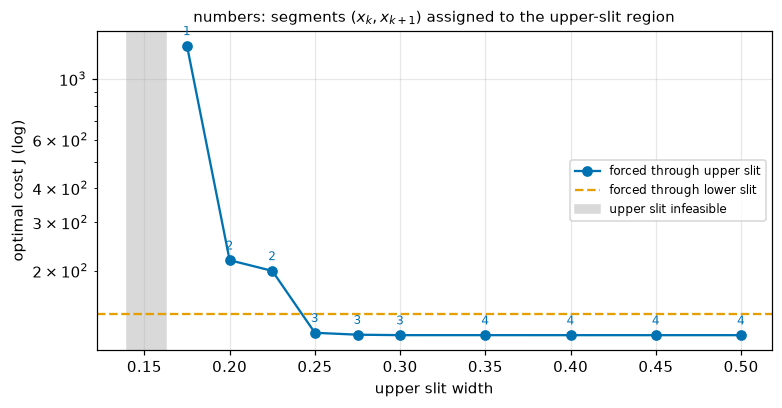

In [22]:
RUN_SWEEP = False
SWEEP_GAPS = [0.5, 0.45, 0.4, 0.35, 0.3, 0.275, 0.25, 0.225, 0.2, 0.175, 0.15]
sweep_file = RESULTS_DIR / "width_sweep.json"

if RUN_SWEEP or not sweep_file.exists():
    lower = solve_algorithm1(double_slit(0.5), forbid=(2,), verbose=False)
    rows = []
    for w in SWEEP_GAPS:
        r = solve_algorithm1(double_slit(w), forbid=(1,), verbose=False)
        rows.append(dict(width=w, feasible=r is not None, J=r and r["J"],
                         J_mean=r and r["J_mean"], J_cov=r and r["J_cov"],
                         pairs_in_slit=r and int(r["M"][2].sum()),
                         peak_vx=r and float(max(m[2] for m in r["mus"]))))
    sweep = dict(lower=dict(J=lower["J"], J_mean=lower["J_mean"], J_cov=lower["J_cov"]), upper=rows)
else:
    sweep = json.loads(sweep_file.read_text())

print(f"lower route (any width): J = {sweep['lower']['J']:.2f}\n")
print(" width   upper J   (mean    + cov )  segments in slit  peak v_x   chosen")
for r in sweep["upper"]:
    if r["feasible"]:
        chosen = "upper" if r["J"] < sweep["lower"]["J"] else "lower"
        print(f" {r['width']:.3f}  {r['J']:8.2f}  ({r['J_mean']:7.2f} + {r['J_cov']:.2f})"
              f"        {r['pairs_in_slit']}            {r['peak_vx']:4.1f}     {chosen}")
    else:
        print(f" {r['width']:.3f}  infeasible                                          lower")

feas = [r for r in sweep["upper"] if r["feasible"]]
fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
ax.plot([r["width"] for r in feas], [r["J"] for r in feas], "o-", color=BLUE, label="forced through upper slit")
for r in feas:
    ax.annotate(str(r["pairs_in_slit"]), (r["width"], r["J"]), textcoords="offset points",
                xytext=(0, 7), ha="center", fontsize=8, color=BLUE)
ax.axhline(sweep["lower"]["J"], color=ORANGE, ls="--", label="forced through lower slit")
inf_w = [r["width"] for r in sweep["upper"] if not r["feasible"]]
if inf_w:
    ax.axvspan(0.14, max(inf_w) + 0.0125, color="0.85", label="upper slit infeasible")
ax.set_yscale("log"); ax.set_xlabel("upper slit width"); ax.set_ylabel("optimal cost J (log)")
ax.set_title("numbers: segments $(x_k,x_{k+1})$ assigned to the upper-slit region")
ax.legend(fontsize=8, loc="center right"); plt.show()

**What it shows.**

- **Width ≥ 0.25:** the upper route costs about 116–119, below the lower route's 139.1, so the planner goes **upper**.
- **Width 0.225 down to 0.175:** the upper route is still **feasible** but costs 200 to 1300, so the planner goes **lower**. At 0.2 (Fig. 4) this is a cost decision, exactly as the paper says.
- **Width 0.15:** the upper slit is infeasible.

**Why the jump?** It comes from the **mean** cost, not the covariance cost. The numbers on the points count how many segments the path spends in the slit band. Each sample inside the slit must satisfy $3.09\,\sigma_y \le$ half the width. Below about 0.25 it becomes cheaper to **dash through the 2-unit-thick wall in fewer time steps** (2 segments instead of 3, peak speed 5.7 instead of 3.8) than to hold $\sigma_y$ that small for one more sample. Kinetic energy costs control effort, so J jumps.

This is partly a **discrete-time effect**: the chance constraints are only imposed at the sample times $k$, so the number of samples inside the slit is what matters. That is a useful caveat when interpreting the paper's results.

---
## 12. Verification by Monte Carlo

The optimizer's answers rest on formulas. Now we simulate each solution 200,000 times with the actual policy and check:

| Check | What it tests |
|---|---|
| terminal mean error | Eq. (18a) |
| $\lambda_{\max}(\Sigma_{x_N}-\Sigma_N)\le 0$ | Eq. (19) |
| worst per-face violation frequency | each chance constraint holds at level $\epsilon$ |
| collision rate at sampled steps | actual safety at $k=0..N$ |
| collision rate along the **continuous** path | safety *between* samples. With acceleration held constant, $p(t)=p_k+v_kt+\tfrac12 u_kt^2$; checked at 10 points per step |

In [23]:
def in_collision(p, geom):
    """True where position p (n x 2) is inside an obstacle or off the map."""
    x, y = p[:, 0], p[:, 1]
    x0, x1, y0, y1 = WORKSPACE
    hit = (x < x0) | (x > x1) | (y < y0) | (y > y1)
    for (a0, a1, b0, b1) in geom["obstacles"]:
        hit |= (x > a0) & (x < a1) & (y > b0) & (y < b1)
    return hit


def verify(res, geom, n_mc=200_000):
    """Formula-side and Monte Carlo checks of one solution (see table above)."""
    mus, Sigmas, M = res["mus"], res["Sigmas"], res["M"]
    xs, _, us, cost = simulate(res["V"], res["K_ks"], n_mc=n_mc, seed=8)
    face_max = 0.0
    for k in range(N):
        box = geom["regions"][int(np.argmax(M[:, k]))]
        for kk in (k, k + 1):
            for i, sgn, b in box_faces(box):
                face_max = max(face_max, np.mean(sgn * xs[kk][:, i] > b))
    hit = np.array([in_collision(x[:, :2], geom) for x in xs])
    any_hit = hit.any(axis=0)
    for k in range(N):
        for t in np.linspace(0, dt, 11)[1:-1]:
            any_hit |= in_collision(xs[k][:, :2] + xs[k][:, 2:] * t + 0.5 * us[k] * t**2, geom)
    return {"route": res["route"], "J (formula)": f"{res['J']:.2f}", "J (MC avg)": f"{cost.mean():.2f}",
            "terminal mean error": f"{np.linalg.norm(mus[-1] - mu_N):.0e}",
            "lmax(Sig_xN - Sig_N)": f"{np.linalg.eigvalsh(Sigmas[-1] - Sigma_N).max():+.1e}",
            "worst face violation": f"{face_max:.5f}",
            "collision, sampled k": f"{hit.mean(axis=1).max():.5f}",
            "traj. collision, continuous": f"{any_hit.mean():.5f}"}


cases = {"slit 0.5, mean": (exp1["mean steering"], geom1),
         "slit 0.5, cov": (exp1["covariance steering"], geom1),
         "slit 0.2, mean": (exp2_mean, geom2),
         "slit 0.2, cov": (exp2, geom2)}
table = {name: verify(res, g) for name, (res, g) in cases.items()}
keys = list(next(iter(table.values())).keys())
print(f"{'':30s}" + "".join(f"{n:>16s}" for n in table))
for key in keys:
    print(f"{key:30s}" + "".join(f"{table[n][key]:>16s}" for n in table))
print(f"\nepsilon = {eps} per face;  MC standard error at p = 1e-3: {np.sqrt(eps / 2e5):.0e}")

                                slit 0.5, mean   slit 0.5, cov  slit 0.2, mean   slit 0.2, cov
route                                    lower           upper           lower           lower
J (formula)                             201.68          116.42          201.68          139.08
J (MC avg)                              201.68          116.41          201.68          139.10
terminal mean error                      5e-10           3e-10           5e-10           2e-09
lmax(Sig_xN - Sig_N)                  +6.9e-02        -1.7e-12        +6.9e-02        -1.4e-11
worst face violation                   0.00111         0.00109         0.00111         0.00114
collision, sampled k                   0.00108         0.00000         0.00108         0.00000
traj. collision, continuous            0.00136         0.00001         0.00136         0.00011

epsilon = 0.001 per face;  MC standard error at p = 1e-3: 7e-05


**How to read the table.**

- **Cost:** formula and simulation agree for every solution.
- **Terminal covariance:** met exactly by covariance steering ($\lambda_{\max}\approx0$, i.e. active). Mean steering misses it by +0.069, as expected, since it cannot shape the covariance and (19) is not imposed on it. The paper notes the same.
- **Per-face violation ≈ 0.001 = ε:** the chance constraints are tight and correct. Values slightly above 0.001 come from taking the *maximum* over many active faces of a noisy estimate (standard error about $7\times10^{-5}$).
- **Collisions:** zero at the sampled steps for covariance steering. Many active faces are band edges far from the wall, which are not real obstacles, so actual collisions are rarer than ε. This is the conservatism of the box decomposition that the paper discusses with its Fig. 6.
- **Between samples:** the continuous-path collision rate is slightly higher (up to about $10^{-4}$). The guarantee holds *per sample*, and the true path between samples is a parabola, not the straight segment the region logic assumes.

In [24]:
# Cross-check against the standalone script's saved solutions, if they exist
for name, res in [("orig_mean", exp1["mean steering"]), ("orig_cov", exp1["covariance steering"]),
                  ("narrow_mean", exp2_mean), ("narrow_cov", exp2)]:
    f = RESULTS_DIR / f"{name}.pkl"
    if f.exists():
        import pickle
        ref = pickle.loads(f.read_bytes())
        print(f"{name:12s} notebook J = {res['J']:9.4f}   script J = {ref['J']:9.4f}   route {res['route']}/{ref['route']}")

orig_mean    notebook J =  201.6833   script J =  201.6833   route lower/lower
orig_cov     notebook J =  116.4226   script J =  116.4226   route upper/upper
narrow_mean  notebook J =  201.6833   script J =  201.6833   route lower/lower
narrow_cov   notebook J =  139.0844   script J =  139.0844   route lower/lower


---
## 13. Summary

| Step | The idea in one line |
|---|---|
| Model (Eq. 1) | Position and velocity integrate the acceleration we choose; noise is added every step. |
| Lifting (Eq. 7) | The whole trajectory is a **linear** function of all controls, so we can optimize them at once. |
| Open loop | Controls move the mean but **cannot** touch the covariance, which only grows. |
| Theorem 1 | Feed back the noise-driven state $y_k$: $X=\bar X+(I+\mathcal BK)Y$. $V$ sets the mean, $K$ the spread, and both stay **convex**. |
| Cost (Eq. 17) | Expected energy = mean part + covariance part (a trace, i.e. a squared Frobenius norm). |
| Terminal (Eq. 19) | "Covariance no larger than target" = ellipse containment = a spectral norm ≤ 1. |
| Chance (Eq. 20) | Keep the mean 3.09 σ inside each wall: an SOC constraint. |
| Obstacles (Alg. 1) | Overlapping convex boxes + one binary per box per step + big-M switches. |
| Solver | MOSEK can't do MI-SDP → SOC cutting planes on (19) + a lower/upper-bound certificate. |

**Findings.**

1. **Reproduced:** covariance steering takes the narrow slit that mean steering cannot use (Fig. 2) and detours when the slit narrows (Fig. 4).
2. Feedback is cheap in itself (covariance cost < 1); its value is in **enabling** cheaper mean paths (116 vs 202).
3. The route switch is driven by the *mean* cost of crossing the wall in fewer samples, partly a discrete-time effect.
4. The probabilistic guarantees hold in simulation, per face and per sample.

**Assumptions to keep in mind:** $\mu_0,\Sigma_0,\Sigma_N,Q,R$ are assumed, and the geometry is reconstructed from the paper's figures.

**Things to try** (each is a one-line change and a re-run):

- Change `eps` to `1e-2` or `1e-5`. How do the margins, routes and costs move?
- Shrink `Sigma_N`. When does the free-space problem in §7 stop being cheap?
- Set `Q_k = 0.1 * np.eye(nx)`. The cost now also penalizes distance from the origin. Does the route change?
- Move the start to `mu_0 = [-10, -1, 0, 0]`. Does the planner still prefer the upper slit?